# 01. Обзор производства: выпуск, план-факт, сезонность

**Вопрос бизнеса.** Директор по производству видит, что в отдельные месяцы план выпуска срывается, а качество «плавает». Прежде чем искать причины, нужно понять общую картину: сколько и чего выпускаем, где и когда отклоняемся от плана, есть ли системные закономерности.

**Данные:** витрины хранилища (`marts.*`), период - 01.10.2024-30.09.2026.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from helpers import q, save, pct, label_end, label_ends, SERIES, BLUE, ORANGE, AQUA, YELLOW, GRAY, GRAY_LIGHT, INK_2

pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))

## 1. Контроль данных перед анализом

In [2]:
q("""
select 'изделий' as what, count(*)::text as value from marts.fct_units
union all select 'операций', count(*)::text from marts.fct_operations
union all select 'испытаний', count(*)::text from marts.fct_tests
union all select 'дефектов (завод)', count(*)::text from marts.fct_defects
union all select 'гарантийных заявок', count(*)::text from marts.fct_warranty_claims
union all select 'период запусков', min(start_date)::text || ' - ' || max(start_date)::text from marts.fct_units
union all select 'заявок с ненайденным VIN', count(*) filter (where is_vin_unmatched)::text from marts.fct_warranty_claims
""")

,what,value
0,заявок с ненайденным VIN,0
1,гарантийных заявок,345
2,дефектов (завод),4098
3,изделий,22227
4,период запусков,2024-10-01 - 2026-09-30
5,операций,113293
6,испытаний,93403


## 2. Ключевые показатели по цехам
Считаем только принятые изделия (прошли испытания). **FPY** (First Pass Yield) - доля изделий, прошедших линию без дефектов и все испытания с первой попытки.

In [3]:
kpi = q("""
select w.workshop_code as "Цех",
       count(*)                                                as "Принято, шт.",
       round(sum(u.price_rub) / 1e9, 2)                        as "Выручка отгрузок, млрд ₽",
       round(avg(u.is_first_pass::int), 3)                     as "FPY",
       round(percentile_cont(0.5) within group (order by u.total_lead_time_h)::numeric, 1) as "Медиана цикла, ч",
       round(sum(u.rework_cost_rub) / 1e6, 2)                  as "Доработки, млн ₽",
       round(sum(u.warranty_cost_rub) / 1e6, 2)                as "Гарантия, млн ₽"
from marts.fct_units u
join marts.dim_workshop w using (workshop_id)
where u.accepted_at is not null
group by w.workshop_code order by 2 desc
""")
kpi

,Цех,"Принято, шт.","Выручка отгрузок, млрд ₽",FPY,"Медиана цикла, ч","Доработки, млн ₽","Гарантия, млн ₽"
0,ЦЛА,13045,30.21,0.83,26.00,3.29,5.68
1,ЦМТ,5118,3.30,0.85,25.40,0.62,0.77
2,ЦГА,2919,32.19,0.79,80.60,2.71,4.99
3,ЦСТ,1076,11.78,0.79,120.20,1.13,4.65


## 3. План-факт по месяцам
Факт - изделия, принятые ОТК в месяце. Первый месяц наблюдений исключён: конвейер «наполняется», часть машин октября 2024 запущена в сентябре (вне выборки).

In [4]:
pf = q("""
select p.month_start, w.workshop_code, sum(p.planned_qty) as plan, sum(p.accepted_qty) as fact
from marts.fct_production_plan p join marts.dim_workshop w using (workshop_id)
where p.month_start > '2024-10-01'
group by 1, 2 order by 1, 2
""")
pf["adherence"] = pf["fact"] / pf["plan"]
pivot = pf.pivot(index="month_start", columns="workshop_code", values="adherence")
pivot.round(3).T

month_start,2024-11-01,2024-12-01,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,...,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01,2026-09-01
workshop_code,,,,,,,,,,,,,,,,,,,,,
ЦГА,1.23,0.97,0.95,1.04,0.88,1.03,1.03,0.98,0.89,1.01,...,1.13,0.94,0.85,0.86,0.86,0.95,1.01,1.03,0.98,1.02
ЦЛА,1.01,0.90,1.04,0.97,1.00,1.01,0.96,0.98,0.95,0.92,...,1.00,0.97,1.01,0.96,0.97,0.96,0.95,0.97,0.95,0.95
ЦМТ,0.86,0.98,1.03,1.07,0.98,0.93,0.93,0.93,1.10,0.94,...,1.07,1.00,0.91,0.95,0.94,1.08,1.05,1.08,0.99,1.02
ЦСТ,1.26,0.90,0.93,0.95,1.01,0.97,0.81,1.00,1.10,0.86,...,1.12,0.95,1.02,0.86,0.82,0.96,0.95,1.07,0.90,0.93


Помесячные отклонения шумные (на малых объёмах ЦСТ и ЦГА одна машина - это 1-2% плана, плюс перенос машин через границу месяца). Для управленческой картины сглаживаем скользящим окном 3 месяца.

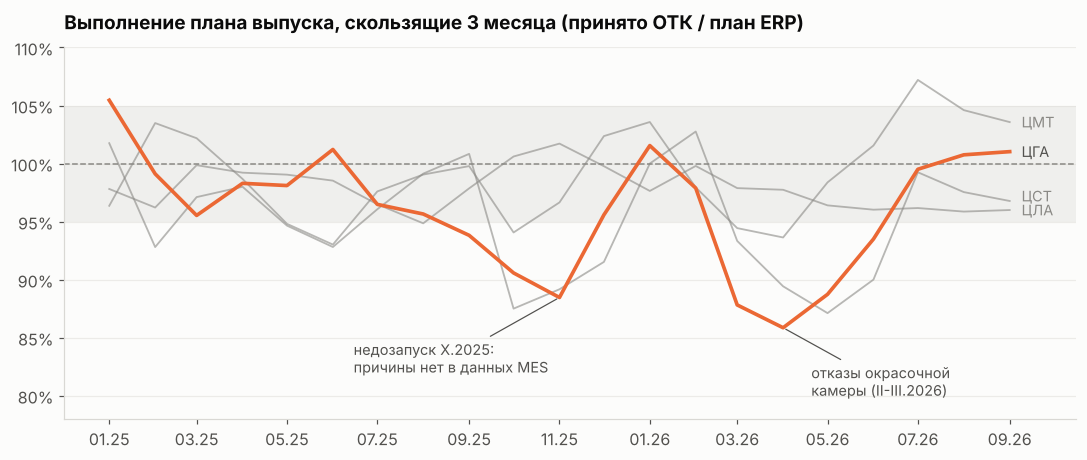

In [5]:
roll_plan = pf.pivot(index="month_start", columns="workshop_code", values="plan").rolling(3).sum()
roll_fact = pf.pivot(index="month_start", columns="workshop_code", values="fact").rolling(3).sum()
roll = (roll_fact / roll_plan).dropna()

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.axhspan(0.95, 1.05, color=GRAY_LIGHT, alpha=0.35, lw=0)
ax.axhline(1, color=GRAY, lw=1, ls="--")
for col in ["ЦЛА", "ЦСТ", "ЦМТ"]:
    ax.plot(roll.index, roll[col], color=GRAY, lw=1.2, alpha=0.6)
ax.plot(roll.index, roll["ЦГА"], color=ORANGE, lw=2.4)
label_ends(ax, roll.index[-1] + pd.Timedelta(days=8),
           {c: (roll[c].iloc[-1], INK_2 if c == "ЦГА" else GRAY) for c in roll.columns}, min_gap=0.012)
ax.annotate("отказы окрасочной\nкамеры (II-III.2026)", xy=(pd.Timestamp("2026-04-01"), roll.loc["2026-04-01", "ЦГА"]),
            xytext=(pd.Timestamp("2026-04-20"), 0.80), arrowprops=dict(arrowstyle="-", color=INK_2, lw=0.8),
            fontsize=9.5, color=INK_2)
ax.annotate("недозапуск X.2025:\nпричины нет в данных MES", xy=(pd.Timestamp("2025-11-01"), roll.loc["2025-11-01", "ЦГА"]),
            xytext=(pd.Timestamp("2025-06-15"), 0.82), arrowprops=dict(arrowstyle="-", color=INK_2, lw=0.8),
            fontsize=9.5, color=INK_2)
pct(ax)
ax.set_ylim(0.78, 1.1)
ax.set_xlim(right=roll.index[-1] + pd.Timedelta(days=45))
ax.set_title("Выполнение плана выпуска, скользящие 3 месяца (принято ОТК / план ERP)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%y"))
save(fig, "01_plan_fact")

Выделяется **ЦГА**: два провала - осенью 2025 и весной 2026 (февраль-апрель - три месяца подряд ниже 87%). Проверим простои участков цеха.

In [6]:
dt = q("""
select month_start, section_full_name, sum(downtime_hours) filter (where not is_planned) as unplanned_h
from marts.mart_downtime_monthly where workshop_code = 'ЦГА'
group by 1, 2 order by 1
""")
dtp = dt.pivot(index="month_start", columns="section_full_name", values="unplanned_h").fillna(0)
dtp.loc["2025-10-01":].round(0)

section_full_name,ЦГА · Окрасочный участок,ЦГА · Участок сборки,ЦГА · Участок сварки кузовов автобусов,ЦГА · Участок сварки рам,ЦГА · Участок финишной регулировки
month_start,,,,,
2025-10-01,0.00,1.00,0.00,2.00,8.00
2025-11-01,0.00,1.00,4.00,4.00,0.00
2025-12-01,0.00,2.00,4.00,4.00,0.00
2026-01-01,2.00,0.00,3.00,0.00,0.00
2026-02-01,44.00,0.00,0.00,7.00,4.00
2026-03-01,97.00,2.00,0.00,0.00,1.00
2026-04-01,1.00,3.00,0.00,0.00,8.00
2026-05-01,3.00,3.00,0.00,0.00,2.00
2026-06-01,0.00,0.00,0.00,2.00,0.00


,reason_name,events,hours,longest_h
0,Отказ оборудования,10,141.00,26.60


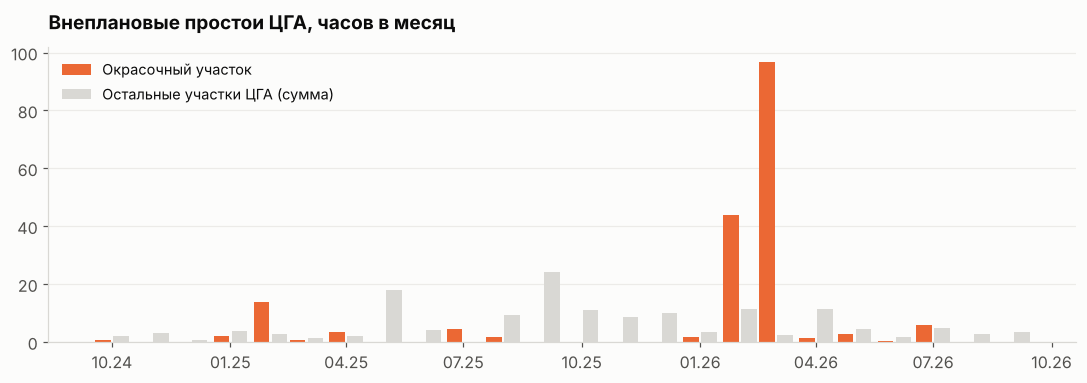

In [7]:
paint = dtp["ЦГА · Окрасочный участок"]
other = dtp.drop(columns="ЦГА · Окрасочный участок").sum(axis=1)
fig, ax = plt.subplots(figsize=(10, 3.6))
w = 12
ax.bar(paint.index - pd.Timedelta(days=7), paint.values, width=w, color=ORANGE, label="Окрасочный участок")
ax.bar(other.index + pd.Timedelta(days=7), other.values, width=w, color=GRAY_LIGHT, label="Остальные участки ЦГА (сумма)")
ax.set_title("Внеплановые простои ЦГА, часов в месяц")
ax.legend(loc="upper left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%y"))
save(fig, "01_downtime_cga")

top = q("""
select reason_name, count(*) as events, round(sum(duration_h), 0) as hours, round(max(duration_h), 1) as longest_h
from marts.fct_downtime d join marts.dim_section s using (section_id)
where s.section_code = 'W2-PNT' and d.work_date between '2026-02-01' and '2026-03-31'
group by 1 order by hours desc
""")
top

**Вывод.** Весенний срыв плана ЦГА объясняется серией отказов окрасочной камеры (февраль-март 2026): 141 час внеплановых простоев за два месяца против 0-6 часов в обычный месяц. Окраска - единственный путь для всех грузовиков и автобусов цеха (узкое место без резерва), поэтому в апреле выпуск ещё догонял очередь.

Осенний провал (октябрь 2025) простоями **не объясняется**: в октябре просто запустили на ~22% меньше машин, чем требовал план (102 против 131), при обычной работе участков. Причина лежит вне MES (комплектующие, кадры, решение ПДО) - это вопрос к планово-диспетчерскому отделу, а не повод подгонять объяснение под данные.

Оценим, сколько выручки «сдвинулось» из-за весеннего недовыпуска (недовыпуск к плану × цена).

In [8]:
lost = q("""
select sum(p.planned_qty - p.accepted_qty) as units_short,
       round(sum((p.planned_qty - p.accepted_qty) * m.list_price_rub) / 1e6, 0) as revenue_shift_mln
from marts.fct_production_plan p join marts.dim_model m using (model_id)
where m.workshop_code = 'ЦГА' and p.month_start between '2026-02-01' and '2026-04-01'
""")
lost

,units_short,revenue_shift_mln
0,58.00,759.00


## 4. Сезонность выпуска
Индекс сезонности - запуски в месяце относительно среднего по группе (без тренда).

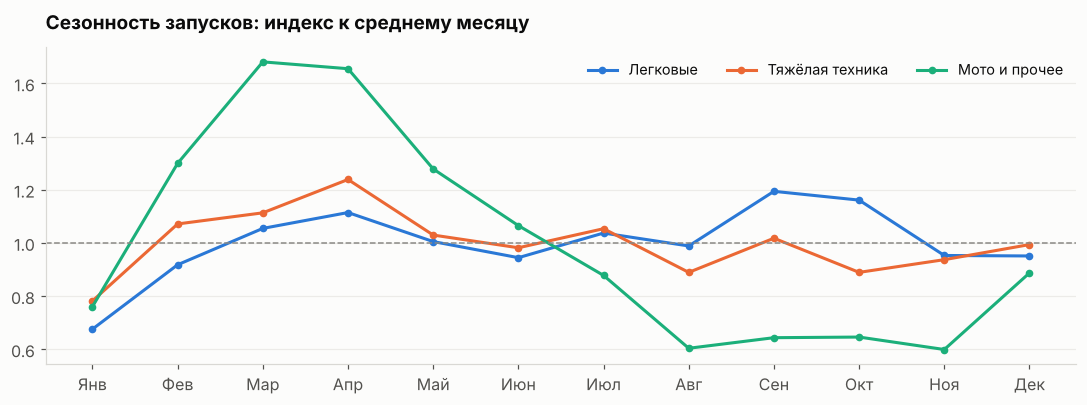

In [9]:
season = q("""
select d.month, dm.product_group, count(*) as units
from marts.fct_units u join marts.dim_model dm using (model_id) join marts.dim_date d on d.date_day = u.start_date
where u.start_date between '2024-10-01' and '2026-09-30'
group by 1, 2
""")
sp = season.pivot(index="month", columns="product_group", values="units")
sp = sp / sp.mean()
fig, ax = plt.subplots(figsize=(10, 3.8))
months = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн", "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"]
for col, c in zip(["Легковые", "Тяжёлая техника", "Мото и прочее"], [BLUE, ORANGE, AQUA]):
    ax.plot(sp.index, sp[col], color=c, marker="o", ms=4, label=col)
ax.axhline(1, color=GRAY, lw=1, ls="--")
ax.set_xticks(range(1, 13), months)
ax.set_title("Сезонность запусков: индекс к среднему месяцу")
ax.legend(loc="upper right", ncol=3)
save(fig, "01_seasonality")

Мототехника и сельхозмашины - выраженно сезонные (пик февраль-апрель под весенний сезон продаж, провал летом). Это важно для планирования персонала: сезонная бригада ЦМТ (февраль-июль 2026) - ответ на пик, и, как покажет ноутбук 02, у неё есть «цена входа» в качестве.

## 5. «Штурмовщина» в конце месяца
Сравним объём запусков и дефектность операций по номеру рабочего дня до конца месяца.

In [10]:
rush = q("""
select d.working_days_to_month_end as wd_to_end,
       count(*) filter (where o.step_no = 1)::numeric / count(distinct o.work_date) as starts_per_day,
       avg(o.caused_defect::int) as defect_rate,
       count(*) as ops
from marts.fct_operations o join marts.dim_date d on d.date_day = o.work_date
where not o.is_rework and d.working_days_to_month_end <= 10
group by 1 order by 1 desc
""")
rush.assign(defect_rate=rush["defect_rate"].map("{:.2%}".format))

,wd_to_end,starts_per_day,defect_rate,ops
0,10,41.96,2.69%,5137
1,9,42.71,3.35%,5020
2,8,43.50,3.39%,5133
3,7,42.12,3.05%,5213
4,6,39.96,2.56%,4800
5,5,42.79,3.52%,5091
6,4,40.04,3.08%,4902
7,3,59.71,4.65%,6499
8,2,59.96,4.68%,7098
9,1,56.71,4.25%,7077


Дефектность: обычные дни 3.18%, последние 3 дня 4.52%, отношение 1.42, χ²-тест p = 1.5e-21


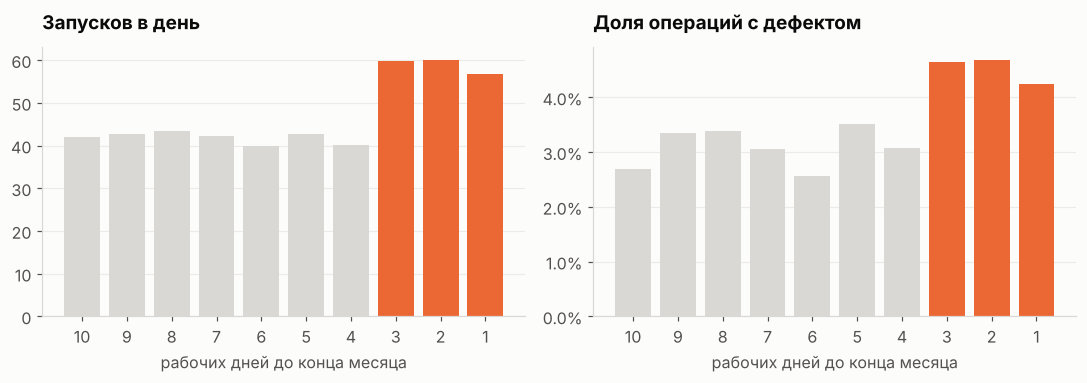

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
colors = [ORANGE if v <= 3 else GRAY_LIGHT for v in rush["wd_to_end"]]
axes[0].bar(rush["wd_to_end"].astype(str), rush["starts_per_day"], color=colors)
axes[0].set_title("Запусков в день")
axes[0].set_xlabel("рабочих дней до конца месяца")
axes[1].bar(rush["wd_to_end"].astype(str), rush["defect_rate"], color=colors)
pct(axes[1], 1)
axes[1].set_title("Доля операций с дефектом")
axes[1].set_xlabel("рабочих дней до конца месяца")
save(fig, "01_month_end_rush")

from scipy.stats import chi2_contingency
ops = q("""
select d.is_month_end_rush, sum(o.caused_defect::int) as defects, count(*) as ops
from marts.fct_operations o join marts.dim_date d on d.date_day = o.work_date
where not o.is_rework group by 1 order by 1
""")
table = np.c_[ops["defects"], ops["ops"] - ops["defects"]]
chi2, p, *_ = chi2_contingency(table)
rate = ops["defects"] / ops["ops"]
print(f"Дефектность: обычные дни {rate[0]:.2%}, последние 3 дня {rate[1]:.2%}, "
      f"отношение {rate[1] / rate[0]:.2f}, χ²-тест p = {p:.1e}")

**Вывод.** В последние 3 рабочих дня месяца запуски растут примерно на треть, а доля дефектных операций - в ~1.4 раза (эффект статистически значим). Это классическая «штурмовщина»: план догоняют в конце месяца ценой качества. Рекомендация - сглаживание графика запусков (выравнивание суточного плана, контроль отклонения от графика с середины месяца), а не наращивание контроля в конце месяца. Денежная оценка - в итоговом отчёте.